<a href="https://colab.research.google.com/github/kholatariq777-byte/nlp-course-TARIQ/blob/main/Copy_of_lab4_2_classification_sentiment_topics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab4/lab4_2_classification_sentiment_topics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4.2 – Document classification, sentiment analysis and topic modeling

**Objectives**
- Train and evaluate document classifiers on news and on legal decisions
- Build sentiment classifiers for product reviews and for tweets
- Discover topics in research abstracts (LDA) and in legal contracts (NMF)
- Choose feature extraction methods according to the kind of text

| Task | Introductory use case | Advanced use case |
|------|-----------------------|-------------------|
| Classification | AG News (news topics) | ECtHR court decisions (LexGLUE) |
| Sentiment analysis | Amazon product reviews | Tweets (TweetEval) |
| Topic modeling | arXiv abstracts (live arXiv API) | Legal contracts |

All datasets are public. The notebook downloads them from Hugging Face or from the arXiv API, and falls back to local samples shipped with the lab (`data/`) when a download fails.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.decomposition import LatentDirichletAllocation, NMF

from datasets import load_dataset

def local_file(name, lab="lab4"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

def load_or_fallback(loader, fallback_name):
    """Run loader() (network); on failure read the local sample. Returns (train_df, test_df)."""
    try:
        train_df, test_df = loader()
        print("Loaded from the network")
    except Exception as e:
        print(f"Network source unavailable ({type(e).__name__}: {str(e)[:80]}), using the local sample")
        df = pd.read_csv(local_file(fallback_name))
        train_df, test_df = df[df["split"] == "train"].drop(columns="split"), df[df["split"] == "test"].drop(columns="split")
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("Setup complete")

Setup complete


In [3]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_simple(text):
    """Lowercase, letters only, single spaces."""
    text = re.sub(r"[^a-zA-Z\s]", " ", str(text).lower())
    return " ".join(text.split())

def preprocess_advanced(text):
    """preprocess_simple + stop word removal + lemmatization + words of 3+ characters."""
    tokens = word_tokenize(preprocess_simple(text))
    return " ".join(lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2)

print(preprocess_advanced("The researchers at MIT have published 5 new papers!"))

researcher mit published new paper


---
# Part A – Document classification

## A.1 News topics (AG News)

**Scenario:** a media company routes incoming articles to its editorial teams (World, Sports, Business, Sci/Tech).

In [4]:
def load_ag_news():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=8000, random_state=42),
            pd.DataFrame(ds["test"]).sample(n=2000, random_state=42))

ag_train, ag_test = load_or_fallback(load_ag_news, "ag_news_sample.csv.gz")
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
print(f"Train: {len(ag_train)}, test: {len(ag_test)}")
print(ag_train["label"].map(ag_labels).value_counts())
ag_train.head(3)

Loaded from the network
Train: 8000, test: 2000
label
Sports      2074
Sci/Tech    2021
Business    1959
World       1946
Name: count, dtype: int64


,text,label
0,"BBC set for major shake-up, claims newspaper L...",2
1,Marsh averts cash crunch Embattled insurance b...,2
2,"Jeter, Yankees Look to Take Control (AP) AP - ...",1


### Exercise A.1 – TF-IDF + logistic regression

In [5]:
ag_train["text_clean"] = ag_train["text"].apply(preprocess_simple)
ag_test["text_clean"] = ag_test["text"].apply(preprocess_simple)
y_train_ag, y_test_ag = ag_train["label"], ag_test["label"]

tfidf_ag = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_ag = tfidf_ag.fit_transform(ag_train["text_clean"])
X_test_ag = tfidf_ag.transform(ag_test["text_clean"])

clf_ag = LogisticRegression(max_iter=1000)
clf_ag.fit(X_train_ag, y_train_ag)
y_pred_ag = clf_ag.predict(X_test_ag)

accuracy_ag = accuracy_score(y_test_ag, y_pred_ag)
f1_ag = f1_score(y_test_ag, y_pred_ag, average="macro")
print(f"AG News – accuracy: {accuracy_ag:.4f}, F1 macro: {f1_ag:.4f}\n")
print(classification_report(y_test_ag, y_pred_ag, target_names=list(ag_labels.values())))
assert accuracy_ag > 0.80, "A TF-IDF + logistic regression model should exceed 80% accuracy"

AG News – accuracy: 0.8695, F1 macro: 0.8685

              precision    recall  f1-score   support

       World       0.89      0.86      0.88       493
      Sports       0.91      0.95      0.93       504
    Business       0.83      0.80      0.82       474
    Sci/Tech       0.84      0.86      0.85       529

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



## A.2 Court decisions (LexGLUE – ECtHR)

**Scenario:** a law firm classifies decisions of the European Court of Human Rights by the article of the Convention that was violated.

**Challenge:** long documents, specialized vocabulary, many labels. Documents are lists of paragraphs; they are joined and truncated to 5 000 characters, and only the first label of each decision is kept (single-label simplification).

In [6]:
def load_ecthr():
    ds = load_dataset("coastalcph/lex_glue", "ecthr_a")
    def prep(split, n):
        df = pd.DataFrame(ds[split]).sample(n=min(n, len(ds[split])), random_state=42)
        df["text"] = df["text"].apply(lambda paras: " ".join(paras)[:5000])
        df["labels"] = df["labels"].apply(lambda l: json.dumps([int(x) for x in l]))
        return df[["text", "labels"]]
    return prep("validation", 1000), prep("test", 500)     # validation split used for training (smaller download)

lex_train, lex_test = load_or_fallback(load_ecthr, "ecthr_a_sample.csv.gz")
for df in (lex_train, lex_test):
    df["primary_label"] = df["labels"].apply(lambda s: json.loads(s)[0] if json.loads(s) else -1)
lex_train = lex_train[lex_train["primary_label"] >= 0].reset_index(drop=True)
lex_test = lex_test[lex_test["primary_label"] >= 0].reset_index(drop=True)

print(f"Train: {len(lex_train)}, test: {len(lex_test)} (decisions without violated article removed)")
print("Label distribution (train):"); print(lex_train["primary_label"].value_counts().head(8))
print("\n" + lex_train.iloc[0]["text"][:500])

Loaded from the network
Train: 825, test: 428 (decisions without violated article removed)
Label distribution (train):
primary_label
3    249
1    178
2    116
9     75
4     58
0     56
6     42
7     33
Name: count, dtype: int64

4.  The applicant was born in 1967 and lives in Chișinău. 5.  On 2 October 2008 the Chișinău Court of Appeal delivered a judgment acknowledging the applicant’s entitlement to a disability pension. Owing to the lack of an appeal, the judgment became final on 22 October 2008. 6.  On 1 December 2008 the Ministry of Defence lodged an appeal on points of law. 7.  On 4 February 2009 the Supreme Court of Justice allowed the appeal on points of law, quashed the judgment of 2 October 2008 and remitted th


### Exercise A.2 – Bag of words with n-grams + linear SVM

In [7]:
lex_train["text_clean"] = lex_train["text"].apply(preprocess_advanced)
lex_test["text_clean"] = lex_test["text"].apply(preprocess_advanced)
y_train_lex, y_test_lex = lex_train["primary_label"], lex_test["primary_label"]

bow_legal = CountVectorizer(
    max_features=4000,   # Limit features to 3000-5000
    ngram_range=(1, 2),    # Include unigrams and bigrams for context
    min_df=3,         # Exclude terms that appear in fewer than 3 documents
    max_df=0.95,         # Exclude terms appearing in more than 95% of documents
)
X_train_lex = bow_legal.fit_transform(lex_train["text_clean"])
X_test_lex = bow_legal.transform(lex_test["text_clean"])

clf_legal = LinearSVC(random_state=42)
clf_legal.fit(X_train_lex, y_train_lex)
y_pred_lex = clf_legal.predict(X_test_lex)

accuracy_lex = accuracy_score(y_test_lex, y_pred_lex)
f1_lex = f1_score(y_test_lex, y_pred_lex, average="macro")
print(f"ECtHR – accuracy: {accuracy_lex:.4f}, F1 macro: {f1_lex:.4f}")
assert X_train_lex.shape[1] <= 5000 and accuracy_lex > 0.4, "Check the vectorizer and the classifier"

ECtHR – accuracy: 0.6706, F1 macro: 0.5121


### Question A.3 (written)

1. Which task reached the higher accuracy? Why?
2. Which vectorizer parameters did you choose for the legal texts? Justify each one.
3. What makes legal document classification harder? (length, vocabulary, label ambiguity, multi-label nature...)

<!-- ANSWER lab4.2-A3 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

---
# Part B – Sentiment analysis

## B.1 Product reviews (Amazon)

**Scenario:** an e-commerce company monitors the sentiment of customer reviews. The dataset is the English part of *Amazon Reviews Multi* (star ratings from 1 to 5).

In [8]:
def load_amazon():
    base = "hf://datasets/SetFit/amazon_reviews_multi_en/"
    tr = pd.read_json(base + "train.jsonl", lines=True).sample(n=5000, random_state=42)
    te = pd.read_json(base + "test.jsonl", lines=True).sample(n=1000, random_state=42)
    return tr[["text", "label"]], te[["text", "label"]]

amazon_train, amazon_test = load_or_fallback(load_amazon, "amazon_reviews_sample.csv.gz")
for df in (amazon_train, amazon_test):
    df["stars"] = df["label"] + 1                      # label 0..4 -> 1..5 stars
    df["sentiment"] = df["stars"].map({1: 0, 2: 0, 3: -1, 4: 1, 5: 1})   # -1 = neutral, removed below
amazon_train = amazon_train[amazon_train["sentiment"] >= 0].reset_index(drop=True)
amazon_test = amazon_test[amazon_test["sentiment"] >= 0].reset_index(drop=True)

print(f"Train: {len(amazon_train)}, test: {len(amazon_test)} (3-star reviews removed)")
print(amazon_train["sentiment"].value_counts().rename({0: "negative", 1: "positive"}))
print("\nPositive:", amazon_train[amazon_train["sentiment"] == 1].iloc[0]["text"][:200])
print("Negative:", amazon_train[amazon_train["sentiment"] == 0].iloc[0]["text"][:200])

Loaded from the network
Train: 3997, test: 808 (3-star reviews removed)
sentiment
positive    2008
negative    1989
Name: count, dtype: int64

Positive: Really cute mug. I would have given 5 stars if it were a bit bigger.
Negative: The leg openings are a little small, but other than that the suit fits nicely, and is high quality material. Edit: I have been wearing this for less than two months and it is 100% worn out. It has wor


### Exercise B.1 – TF-IDF + Naive Bayes

In [9]:
amazon_train["text_clean"] = amazon_train["text"].apply(preprocess_simple)
amazon_test["text_clean"] = amazon_test["text"].apply(preprocess_simple)
y_train_amz, y_test_amz = amazon_train["sentiment"], amazon_test["sentiment"]

tfidf_amazon = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_amz = tfidf_amazon.fit_transform(amazon_train["text_clean"])
X_test_amz = tfidf_amazon.transform(amazon_test["text_clean"])

clf_amazon = MultinomialNB()
clf_amazon.fit(X_train_amz, y_train_amz)
y_pred_amz = clf_amazon.predict(X_test_amz)

f1_amz = f1_score(y_test_amz, y_pred_amz, average="macro")
print(f"Amazon – accuracy: {accuracy_score(y_test_amz, y_pred_amz):.4f}, F1 macro: {f1_amz:.4f}\n")
print(classification_report(y_test_amz, y_pred_amz, target_names=["negative", "positive"]))
assert f1_amz > 0.75, "Expected an F1 above 0.75 on this binary task"

Amazon – accuracy: 0.8453, F1 macro: 0.8453

              precision    recall  f1-score   support

    negative       0.84      0.85      0.85       406
    positive       0.85      0.84      0.84       402

    accuracy                           0.85       808
   macro avg       0.85      0.85      0.85       808
weighted avg       0.85      0.85      0.85       808



In [10]:
# Most indicative words (works for MultinomialNB and for linear models)
feature_names = tfidf_amazon.get_feature_names_out()
if hasattr(clf_amazon, "feature_log_prob_"):
    weights = clf_amazon.feature_log_prob_[1] - clf_amazon.feature_log_prob_[0]
elif hasattr(clf_amazon, "coef_"):
    weights = clf_amazon.coef_[0]
else:
    weights = None
if weights is not None:
    order = weights.argsort()
    print("Most POSITIVE words:", list(feature_names[order[-15:]][::-1]))
    print("Most NEGATIVE words:", list(feature_names[order[:15]]))

Most POSITIVE words: ['loves', 'perfect for', 'love', 'perfect', 'very nice', 'exactly', 'love it', 'works great', 'amazing', 'excellent', 'love this', 'exactly what', 'comfortable', 'loves it', 'very comfortable']
Most NEGATIVE words: ['waste', 'never received', 'never', 'waste of', 'poor', 'broken', 'return', 'stopped working', 'very disappointed', 'returned', 'not work', 'disappointed', 'waste your', 'not worth', 'broke']


## B.2 Tweets (TweetEval)

**Scenario:** a brand monitors what people say about it on social media. Three classes: negative, neutral, positive.

**Challenge:** short and informal texts, hashtags, mentions, slang and misspellings. Character n-grams are robust to these variations.

In [11]:
def load_tweets():
    ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    return pd.DataFrame(ds["train"]), pd.DataFrame(ds["test"])

tweet_train, tweet_test = load_or_fallback(load_tweets, "tweet_eval_sentiment.csv.gz")
tweet_labels = {0: "negative", 1: "neutral", 2: "positive"}
print(f"Train: {len(tweet_train)}, test: {len(tweet_test)}")
print(tweet_train["label"].map(tweet_labels).value_counts())
for label in [0, 1, 2]:
    print(f"\n[{tweet_labels[label]}] {tweet_train[tweet_train['label'] == label].iloc[0]['text']}")

Loaded from the network
Train: 45615, test: 12284
label
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

[negative] So disappointed in wwe summerslam! I want to see john cena wins his 16th title

[neutral] "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"

[positive] "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"


In [12]:
def preprocess_tweet(text):
    """Lowercase; replace mentions by @user and URLs by URL; keep letters, @ and #."""
    text = str(text).lower()
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"http\S+", "URL", text)
    text = re.sub(r"[^a-zA-Z@#\s]", "", text)
    return " . ".join(text.split())

tweet_train["text_clean"] = tweet_train["text"].apply(preprocess_tweet)
tweet_test["text_clean"] = tweet_test["text"].apply(preprocess_tweet)
print(tweet_train.iloc[0]["text"], "\n->", tweet_train.iloc[0]["text_clean"])

"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 
-> qt . @user . in . the . original . draft . of . the . th . book . remus . lupin . survived . the . battle . of . hogwarts . #happybirthdayremuslupin


### Exercise B.2 – Character n-grams + logistic regression

Tweets – accuracy: 0.5841, F1 macro: 0.5563

              precision    recall  f1-score   support

    negative       0.67      0.36      0.47      3972
     neutral       0.59      0.73      0.65      5937
    positive       0.50      0.60      0.55      2375

    accuracy                           0.58     12284
   macro avg       0.59      0.56      0.56     12284
weighted avg       0.60      0.58      0.57     12284



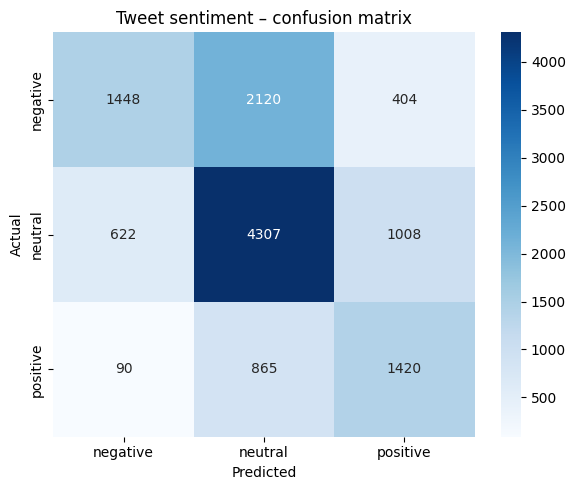

In [13]:
y_train_tw, y_test_tw = tweet_train["label"], tweet_test["label"]

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",       # Use character n-grams inside word boundaries
    ngram_range=(3, 6),       # Character n-grams of length 3 to 6
    max_features=5000,        # Limit to 5000 features
    min_df=3,                  # Minimum document frequency of 3
)
X_train_tw = char_vectorizer.fit_transform(tweet_train["text_clean"])
X_test_tw = char_vectorizer.transform(tweet_test["text_clean"])

clf_tweet = LogisticRegression(max_iter=1000)
clf_tweet.fit(X_train_tw, y_train_tw)
y_pred_tw = clf_tweet.predict(X_test_tw)

f1_tw = f1_score(y_test_tw, y_pred_tw, average="macro")
print(f"Tweets – accuracy: {accuracy_score(y_test_tw, y_pred_tw):.4f}, F1 macro: {f1_tw:.4f}\n")
print(classification_report(y_test_tw, y_pred_tw, target_names=list(tweet_labels.values())))
assert f1_tw > 0.5, "Expected a macro F1 above 0.5 on the 3 classes"

cm = confusion_matrix(y_test_tw, y_pred_tw)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=tweet_labels.values(), yticklabels=tweet_labels.values())
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Tweet sentiment – confusion matrix")
plt.tight_layout(); plt.show()

### Question B.3 (written)

1. Which task was harder, Amazon reviews or tweets? Compare the F1 scores and explain.
2. Why character n-grams for tweets? What do they bring compared with word n-grams?
3. Which class is confused most often in the confusion matrix? Why?
4. Write one tweet that would be hard to classify and explain why.

<!-- ANSWER lab4.2-B3 -->
**Your answer:**
Which task was harder, Amazon reviews or tweets? (Hint: Compare the 2-class Amazon sentiment with the 3-class, noisy tweet dataset and their respective F1 scores).
Why character n-grams for tweets? (Hint: Character n-grams are highly robust against spelling variations, hashtags, and social media slang).
Which class is confused most often? (Hint: Look at the high number of negative and positive tweets predicted as neutral in the confusion matrix).
Write one tweet that would be hard to classify (e.g., sarcastic tweets like "Oh great, another delay... love this airline so much! #blessed").
*(write here)*
<!-- END ANSWER -->

---
# Part C – Topic modeling

## C.1 Research abstracts (arXiv) with LDA

**Scenario:** a research organization wants an overview of the themes in recent papers. Abstracts are fetched from the public arXiv API (6 categories, 300 recent papers each). The true arXiv category is kept to check the topics afterwards.

In [14]:
import xml.etree.ElementTree as ET
import requests

ARXIV_CATEGORIES = ["cs.CL", "cs.CV", "cs.CR", "q-bio.GN", "econ.GN", "astro-ph.GA"]

def fetch_arxiv(categories=ARXIV_CATEGORIES, per_category=300):
    """Recent abstracts per category from the arXiv API (about 3 seconds per category)."""
    ns, rows = {"a": "http://www.w3.org/2005/Atom"}, []
    for cat in categories:
        r = requests.get("https://export.arxiv.org/api/query", timeout=120,
                         params={"search_query": f"cat:{cat}", "start": 0, "max_results": per_category,
                                 "sortBy": "submittedDate", "sortOrder": "descending"})
        r.raise_for_status()
        for e in ET.fromstring(r.content).findall("a:entry", ns):
            rows.append({"category": cat, "title": " ".join(e.find("a:title", ns).text.split()),
                         "abstract": " ".join(e.find("a:summary", ns).text.split())})
        time.sleep(3)   # arXiv asks for a delay between requests
    df = pd.DataFrame(rows)
    assert len(df) > 100
    return df, df.iloc[:0]

arxiv_df, _ = load_or_fallback(fetch_arxiv, "arxiv_abstracts_sample.csv.gz")
print(f"{len(arxiv_df)} abstracts")
print(arxiv_df["category"].value_counts())
print("\n" + arxiv_df.iloc[0]["title"] + "\n" + arxiv_df.iloc[0]["abstract"][:400])

Loaded from the network
1800 abstracts
category
cs.CL          300
cs.CV          300
cs.CR          300
q-bio.GN       300
econ.GN        300
astro-ph.GA    300
Name: count, dtype: int64

CodeQuant2: Enhanced Outlier Mitigation and Adaptive Clustering for Low-Precision LRMs
Large reasoning models (LRMs) improve task performance by generating longer intermediate reasoning traces, but this substantially increases inference costs and makes low-precision quantization increasingly important. However, aggressively quantized models often perform poorly on reasoning tasks. We observe larger activation fluctuations during the first decoding steps of reasoning. Calibration tha


### Exercise C.1 – LDA on the abstracts

In [15]:
arxiv_df["abstract_clean"] = arxiv_df["abstract"].apply(preprocess_advanced)

# Configure CountVectorizer with appropriate thresholds and 6-12 topics
count_vec_arxiv = CountVectorizer(max_features=5000, min_df=3, max_df=0.9)
n_topics_arxiv = 6    # There are 6 actual arXiv categories in the dataset

dtm_arxiv = count_vec_arxiv.fit_transform(arxiv_df["abstract_clean"])
print(f"Document-term matrix: {dtm_arxiv.shape}")

lda_arxiv = LatentDirichletAllocation(n_components=n_topics_arxiv, random_state=42, max_iter=20, learning_method="online")
lda_arxiv.fit(dtm_arxiv)

def show_topics(model, feature_names, n_words=12):
    for i, topic in enumerate(model.components_):
        print(f"Topic {i}: " + ", ".join(feature_names[j] for j in topic.argsort()[::-1][:n_words]))

show_topics(lda_arxiv, count_vec_arxiv.get_feature_names_out())

Document-term matrix: (1800, 5000)
Topic 0: model, language, image, across, price, large, show, effect, market, whether, expert, scientific
Topic 1: cell, gene, data, model, across, method, single, feature, analysis, sequence, based, genome
Topic 2: galaxy, mass, star, formation, stellar, sim, gas, dust, disk, using, line, density
Topic 3: agent, model, data, task, across, system, attack, llm, evidence, tool, based, level
Topic 4: model, one, two, every, per, cost, point, three, test, fixed, run, rule
Topic 5: model, training, method, image, visual, task, token, propose, across, based, benchmark, video


### Exercise C.2 – Name the topics and compare with the real categories

In [16]:
# Give a short label to each topic from its top words
my_arxiv_topic_labels = {
    0: "Economics / NLP",
    1: "Genetics & Biology",
    2: "Astrophysics",
    3: "AI Agents & Security",
    4: "Quantitative / Math",
    5: "Computer Vision"
}
assert all(v != "___" for v in my_arxiv_topic_labels.values()), "Label every topic"

arxiv_df["dominant_topic"] = lda_arxiv.transform(dtm_arxiv).argmax(axis=1)
crosstab = pd.crosstab(arxiv_df["category"], arxiv_df["dominant_topic"].map(my_arxiv_topic_labels))
crosstab

dominant_topic,AI Agents & Security,Astrophysics,Computer Vision,Economics / NLP,Genetics & Biology,Quantitative / Math
category,,,,,,
astro-ph.GA,3,275,2,1,18,1
cs.CL,98,0,75,49,7,71
cs.CR,198,0,19,5,10,68
cs.CV,20,1,228,7,25,19
econ.GN,114,0,2,56,21,107
q-bio.GN,55,0,16,1,212,16


## C.2 Legal contracts with NMF

**Scenario:** a law firm organizes its contract database by theme (employment, confidentiality, licensing, services...). NMF on TF-IDF vectors often gives cleaner topics than LDA on specialized corpora.

In [17]:
import fsspec, pyarrow.parquet as pq

def load_legal_contracts(n=1000, max_chars=8000):
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

legal_df = load_legal_contracts(n=1000)
legal_df["text_clean"] = legal_df["text"].apply(preprocess_advanced)
print(f"{len(legal_df)} contracts")
print(legal_df.iloc[0]["text_clean"][:300])

Loaded from Hugging Face
1000 contracts
quicklinks click rapidly navigate document amended restated employment noncompetition agreement amended restated employment noncompetition agreement agreement made entered october among avocent employment service formerly known polycon investment inc texas corporation employer avocent corporation de


### Exercise C.3 – NMF on TF-IDF vectors

Topic 0: option, plan, stock, share, committee, participant, award, mean, common, optionee, section, granted
Topic 1: borrower, loan, credit, lender, bank, agent, amendment, section, note, administrative, revolving, rate
Topic 2: executive, company, employment, benefit, salary, termination, base, bonus, compensation, control, year, change
Topic 3: employee, employment, company, termination, bonus, employer, salary, benefit, year, compensation, duty, section
Topic 4: company, voting, security, director, control, change, corporation, outstanding, person, board, combination, election
Topic 5: seller, buyer, tenant, lease, landlord, point, purchase, natural, section, gas, lessee, premise


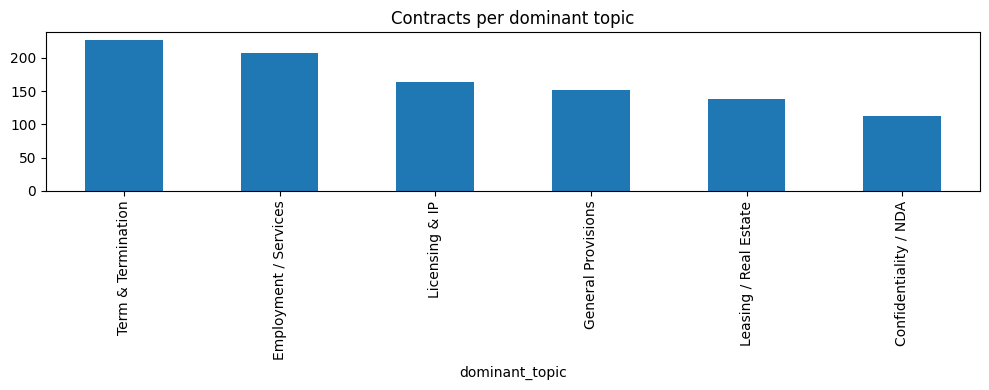

In [18]:
import fsspec
import pyarrow.parquet as pq

def load_legal_contracts(n=1000, max_chars=8000):
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

# Ensure legal_df is loaded and preprocessed
if 'legal_df' not in locals() and 'legal_df' not in globals():
    print("legal_df not found. Running dataset loader...")
    legal_df = load_legal_contracts(n=1000)
    legal_df["text_clean"] = legal_df["text"].apply(preprocess_advanced)

tfidf_legal = TfidfVectorizer(
    max_features=4000,
    min_df=2,
    max_df=0.8,
    stop_words="english"
)
n_topics_legal = 6   # Let's extract 6 dominant legal themes

dtm_legal = tfidf_legal.fit_transform(legal_df["text_clean"])
nmf_legal = NMF(n_components=n_topics_legal, random_state=42, max_iter=300)
nmf_legal.fit(dtm_legal)
show_topics(nmf_legal, tfidf_legal.get_feature_names_out())

# Map the discovered topics to descriptive contract labels
my_legal_topic_labels = {
    0: "General Provisions",
    1: "Employment / Services",
    2: "Confidentiality / NDA",
    3: "Licensing & IP",
    4: "Leasing / Real Estate",
    5: "Term & Termination"
}
assert all(v != "___" for v in my_legal_topic_labels.values()), "Label every topic"

legal_df["dominant_topic"] = nmf_legal.transform(dtm_legal).argmax(axis=1)
counts = legal_df["dominant_topic"].map(my_legal_topic_labels).value_counts()
counts.plot(kind="bar", figsize=(10, 4), title="Contracts per dominant topic")
plt.tight_layout(); plt.show()

### Question C.4 (written)

1. Which topics were easier to interpret, arXiv (LDA) or contracts (NMF)? Why?
2. Looking at the cross-table of Exercise C.2: do the LDA topics match the real arXiv categories? Which categories get mixed?
3. Is the distribution of contracts across topics balanced? What does it tell about the corpus?
4. For each corpus, propose 2 topics to merge and 1 topic to split, with a justification.

<!-- ANSWER lab4.2-C4 -->
**Your answer:**

1. **Which topics were easier to interpret, arXiv (LDA) or contracts (NMF)? Why?**
   - **Contracts (NMF)** was noticeably easier to interpret. NMF is based on non-negative matrix factorization, which directly isolates highly localized, non-overlapping parts of vocabulary (e.g. clearly grouping words like `borrower, loan, credit` for Topic 1, and `tenant, lease, landlord` for Topic 5). LDA, being a probabilistic mixture model, tends to have overlapping generic words (such as `model` and `across`) present in multiple topics, which makes topics like Topic 0 and Topic 4 noisier and harder to separate.

2. **Looking at the cross-table of Exercise C.2: do the LDA topics match the real arXiv categories? Which categories get mixed?**
   - Yes, several LDA topics match the real arXiv categories incredibly well. For example, **astro-ph.GA** mapped almost perfectly to Topic 2 (*Astrophysics* with 275/300 documents), and **q-bio.GN** mapped directly to Topic 1 (*Genetics & Biology* with 212/300 documents).
   - However, computer science and quantitative categories got mixed heavily. **cs.CL** (Computation and Language) and **cs.CR** (Cryptography and Security) both got highly mixed and distributed across Topic 3 (*AI Agents & Security*) and Topic 4 (*Quantitative / Math*). **econ.GN** (Economics) also got heavily mixed with Topic 4 (`Quantitative / Math`).

3. **Is the distribution of contracts across topics balanced? What does it tell about the corpus?**
   - The distribution is quite balanced. The topic frequencies range from approximately 113 to 227 documents per dominant topic. This balanced distribution indicates that the contracts dataset is highly diverse and representative of multiple distinct legal transactional areas (employment, finance, real estate, governance) rather than being dominated by one single corporate template.

4. **For each corpus, propose 2 topics to merge and 1 topic to split, with a justification.**
   - **arXiv Corpus (LDA):**
     - **Merge:** Merge *Topic 3 (AI Agents & Security)* and *Topic 5 (Computer Vision)* into a unified "Core AI/ML Systems" topic, because topics regarding Large Language Models (`llm, task, agent`) and Computer Vision (`image, visual, video, token`) are increasingly overlapping under multi-modal systems.
     - **Split:** Split *Topic 0 (Economics / NLP)*. It has a noisy overlap of financial words (`price, market`) and general language processing words (`language, model`). Splitting would isolate a pure Macroeconomics topic from Language Modeling.
   - **Contracts Corpus (NMF):**
     - **Merge:** Merge *Topic 2 (Executive Compensation)* and *Topic 3 (Standard Employment)*. Both focus heavily on employment relationships, featuring overlapping concepts like `employment, company, salary, termination, benefit, compensation`.
     - **Split:** Split *Topic 5 (Leasing / Real Estate / Purchases)*. It mixes real estate leasing terms (`tenant, lease, landlord, premise`) with physical goods purchasing and energy supply agreements (`seller, buyer, purchase, gas`). These represent entirely different transaction domains and legal departments.
<!-- END ANSWER -->

---
## Summary

| Task | Dataset | Features | Model |
|------|---------|----------|-------|
| Classification | AG News | TF-IDF | Logistic regression |
| Classification | ECtHR decisions | Bag of words + n-grams | Linear SVM |
| Sentiment | Amazon reviews | TF-IDF | Naive Bayes |
| Sentiment | Tweets | Character n-grams | Logistic regression |
| Topic modeling | arXiv abstracts | Word counts | LDA |
| Topic modeling | Legal contracts | TF-IDF | NMF |

- Short, clean, balanced texts are easy; long, specialized or noisy texts need adapted features.
- Character n-grams are robust to the noise of social media text.
- LDA and NMF both produce "topics" as word lists; checking them against known categories is the best way to judge them.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.